Importing Libraries

In [382]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [383]:
@jit(nopython=True)
def Pressure(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def chemical_potential(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def energy_density(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

constructing EoS :

In [384]:
# Initial Values :

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
K_had = 17906.60
m0_had = 939.56

pressure_transition = 63.177
energy_density_transition = 318.26
energy_density_transition_jump = 253.89
energy_density_quark = energy_density_transition + energy_density_transition_jump

n_quark = np.linspace(0.5344,2,1000)
Gam_quark = 2.5
K_quark = pressure_transition / (n_quark[0] ** Gam_quark)
m0_quark = (energy_density_quark - (K_quark * (n_quark[0] ** Gam_quark)) / (Gam_quark - 1)) / n_quark[0]

n_total = np.linspace(0.16,1,2000)

EoS Hadronic

In [385]:
pressure_had = Pressure(n_total, K_had, Gam_had)
chemical_potential_had = chemical_potential(n_total, K_had, Gam_had, m0_had)
energy_density_had = energy_density(n_total, K_had, Gam_had, m0_had)

EoS Quark

In [386]:
pressure_quark = Pressure(n_total, K_quark, Gam_quark)
chemical_potential_quark = chemical_potential(n_total, K_quark, Gam_quark, m0_quark)
energy_density_quark = energy_density(n_total, K_quark, Gam_quark, m0_quark)

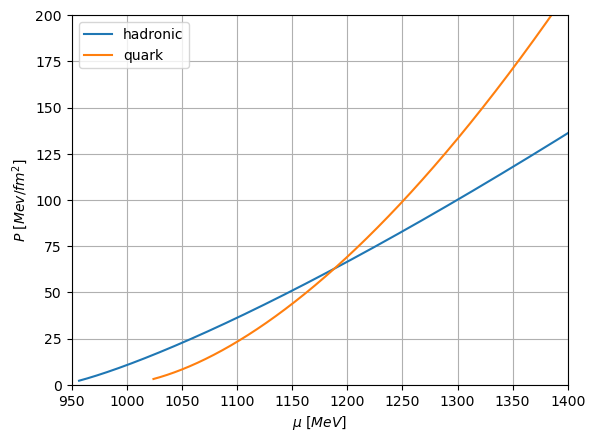

In [387]:
plt.plot(chemical_potential_had, pressure_had, label = "hadronic")
plt.plot(chemical_potential_quark,pressure_quark, label = "quark")

plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [388]:
mu_quark_new = []
for i in range(100):
    mu_quark_0 = (chemical_potential_quark - 50 + i)
    mu_quark_new.append(mu_quark_0)

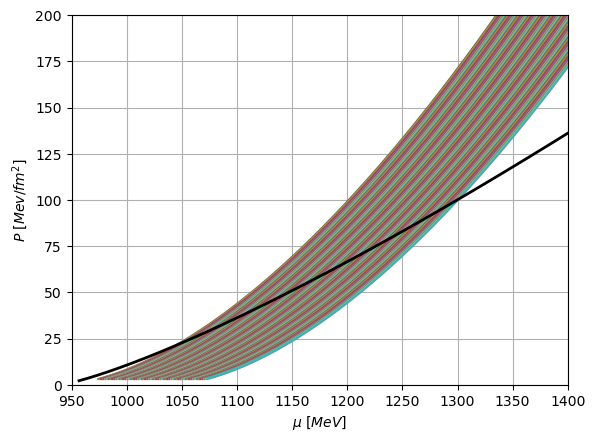

In [389]:
for i in range(len(mu_quark_new)):  # Assuming mu_quark_new is a list of lists
    plt.plot(mu_quark_new[i], pressure_quark, label=f"quark set {i+1}")

plt.plot(chemical_potential_had, pressure_had, label="hadronic", color='black', linewidth=2)  # Hadronic plot
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))  # Adjust legend position to handle many labels
plt.grid()
plt.show()

In [390]:
mu_quark_set

array([1073.10546083, 1073.23270687, 1073.36011969, ..., 1544.55181675,
       1544.86962302, 1545.1874961 ])

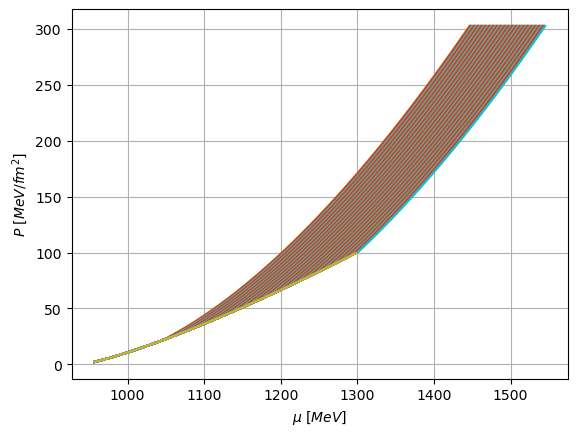

In [391]:
x1 = np.array(chemical_potential_had)
y1 = np.array(pressure_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# List to store combined curves for each quark phase
combined_mu_curves_quark, combined_mu_curves_had = [], []
combined_P_curves_quark, combined_P_curves_had = [], []
P_crit = []
mu_crit = []

combined_mu_curves, combined_p_curves = [], []
index_points =[]

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(pressure_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), max(mu_quark_set), 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

    # Get the approximate intersection point
    x_intersect = mu_new[index_intersect]

    # Find the closest index in the original arrays to this intersection point
    index_had_closest = (np.abs(x1 - x_intersect)).argmin()
    index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

    index_points.append(index_had_closest)

    # Slice the original arrays at the closest intersection points
    mu_had_1 = x1[:index_had_closest]
    P_had = y1[:index_had_closest]
    mu_quark_2 = x2[index_quark_closest:]
    P_quark_2 = y2[index_quark_closest:]

    P_crit.append(P_quark_2[0])
    mu_crit.append(mu_quark_2[0])

    # Combine the original arrays at the intersection point
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    combined_mu_curves.append(combined_mu)
    combined_p_curves.append(combined_P)

    # Store the combined curves in the list
    combined_mu_curves_quark.append(mu_quark_2)
    combined_P_curves_quark.append(P_quark_2)

    # Store the combined curves in the list
    combined_mu_curves_had.append(mu_had_1)
    combined_P_curves_had.append(P_had)

# Plot the combined curves
for i in range(len(combined_mu_curves_had)):
    plt.plot(combined_mu_curves_had[i], combined_P_curves_had[i], label=f"Combined Curve {i+1}")
    plt.plot(combined_mu_curves_quark[i], combined_P_curves_quark[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Uncomment if legend is needed
plt.grid()
plt.show()


In [362]:
def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

In [363]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []
combined_cs2_11 = []
# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    # Compute the gradient of P with respect to mu
    gradient_1 = np.gradient(P_curve_1, mu_curve_1)
    gradient_2 = np.gradient(P_curve_2, mu_curve_2)

    e_curve_1 = (gradient_1*mu_curve_1)-P_curve_1
    cs2_1 = np.gradient(P_curve_1,e_curve_1)

    e_curve_2 = (gradient_2*mu_curve_2)-P_curve_2
    cs2_2 = np.gradient(P_curve_2,e_curve_2)

    P_curve_22 = np.linspace(P_curve_1[-1],P_curve_1[-1],10)
    mu_curve_22 = np.linspace(mu_curve_1[-1],mu_curve_1[-1],10)
    e_curve_22 = np.linspace(e_curve_1[-1],e_curve_2[0],10)
    cs2_22 = np.gradient(P_curve_22,e_curve_22)

    combined_n.append(np.concatenate((gradient_1,gradient_2)))
    combined_e.append(np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2.append(np.concatenate((cs2_1,cs2_22,cs2_2)))
    combined_p_1.append(np.concatenate((P_curve_1,P_curve_22,P_curve_2)))
    combined_mu_1.append(np.concatenate((mu_curve_1,mu_curve_22,mu_curve_2)))


    cs2_11 = np.gradient(np.concatenate((P_curve_1,P_curve_22,P_curve_2)),np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2_11.append(cs2_11)


/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1243: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1244: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1250: RuntimeWarning: invalid value encountered in add
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]


In [364]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []

# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    P_11 = np.concatenate((P_curve_1,P_curve_2))
    mu_11 = np.concatenate((mu_curve_1,mu_curve_2))

    gradient_11 = gradient(P_11, mu_11)
    e_11 = (gradient_11*mu_11[:-1])-P_11[:-1]
    combined_cs2.append(gradient(P_11[:-1],e_11))
    combined_n.append(gradient_11)
    combined_e.append(e_11)
    combined_p_1.append(P_11)
    combined_mu_1.append(mu_11)



def pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,n):
    for i in range(len(combined_cs2)):
        combined_mu_1[i]=np.delete(combined_mu_1[i],index_points[i]-n)
        combined_e[i]=np.delete(combined_e[i],index_points[i]-n)
        combined_p_1[i]=np.delete(combined_p_1[i],index_points[i]-n)
        combined_cs2[i]=np.delete(combined_cs2[i],index_points[i]-n)
    return()
    


In [365]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

In [366]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

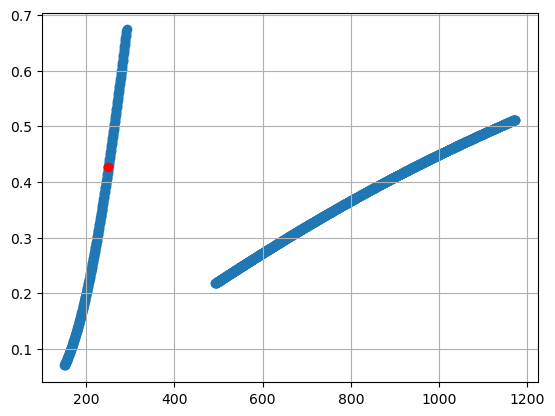

In [367]:
plt.scatter(combined_e[30][:-1],combined_cs2[30])
plt.scatter(combined_e[30][:-1][238],combined_cs2[30][238],color = 'red')
plt.grid()
plt.show()

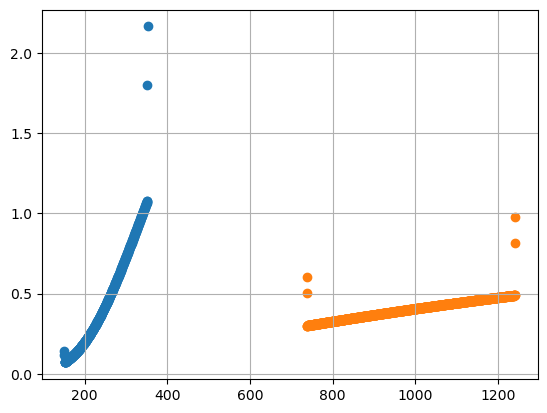

In [368]:
plt.scatter(e_curve_1,cs2_1)
plt.scatter(e_curve_2,cs2_2)
plt.grid()
plt.show()

In [369]:
mu_curve_1[-1]

1298.8498404772072

In [370]:
mu_curve_2[0]

1301.2786849161625

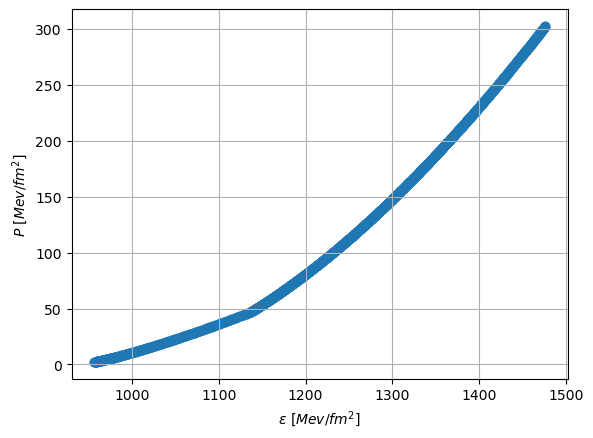

In [371]:
plt.scatter(mu_total[30],p_total[30]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

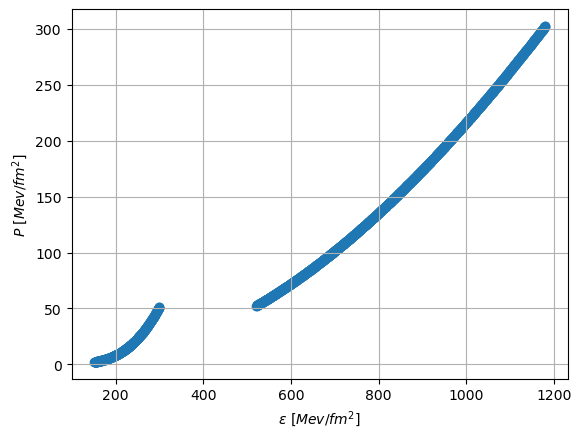

In [372]:
plt.scatter(combined_e[37],combined_p_1[37][:-1]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

In [373]:
e_total, p_total, mu_total, cs_total = combined_e, combined_p_1, combined_mu_1, combined_cs2

In [374]:
e_total

[array([ 151.08430517,  151.48634409,  151.88845752, ..., 1142.05196167,
        1142.65939714, 1143.26696617]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1143.05091115,
        1143.65876684, 1144.26675607]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1144.04986063,
        1144.65813653, 1145.26654597]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1145.04881011,
        1145.65750622, 1146.26633587]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1146.0477596 ,
        1146.65687591, 1147.26612578]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1147.04670908,
        1147.6562456 , 1148.26591568]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1148.04565856,
        1148.6556153 , 1149.26570558]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1149.04460804,
        1149.65498499, 1150.26549548]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1150.04355753,
        1150.65435468, 

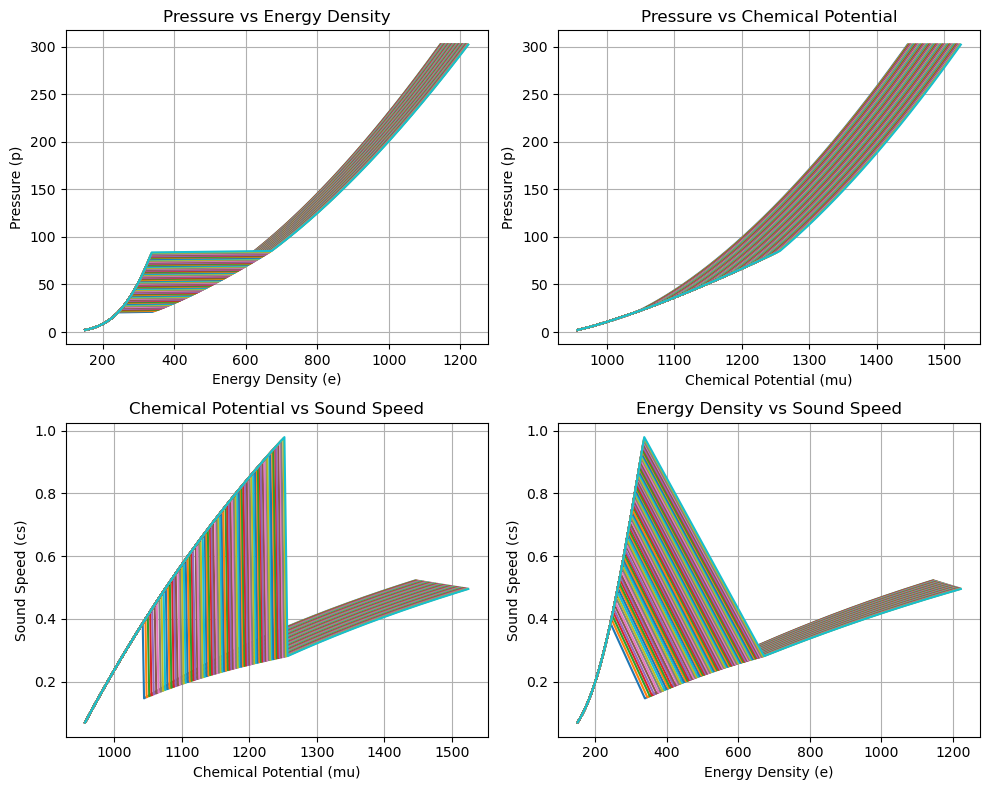

In [375]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i in range(len(p_total)-20):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i][:-1])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i][:-1], p_total[i][:-1])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i][:-2], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i][:-1], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [376]:
delta_P_optimal_1 = []
b_optimal_1 = []
a_optimal_1 = []
P_optimal_1 = []
min_distance_points_1 = []
min_distances_1 = []

P_all_max = []
# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)
    delta_P = np.linspace(P_crit[index]*0.01,P_crit[index]*0.3,1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    a_optimal_1.append(a_optimal)
    b_optimal_1.append(b_optimal)
    P_optimal_1.append(P_optimal)
    delta_P_optimal_1.append(delta_P_optimal)
    min_distance_points_1.append(min_distance_points)
    min_distances_1.append(min_distances)

KeyboardInterrupt: 

In [ ]:
P_optimal_1

[[23.689338468934746,
  23.695475164682765,
  23.701611860430784,
  23.7077485561788,
  23.71388525192682,
  23.720021947674837,
  23.726158643422856,
  23.73229533917087,
  23.73843203491889,
  23.74456873066691,
  23.750705426414925,
  23.756842122162944,
  23.762978817910962,
  23.76911551365898,
  23.775252209406997,
  23.781388905155016,
  23.787525600903034,
  23.79366229665105,
  23.79979899239907,
  23.805935688147088,
  23.812072383895106,
  23.818209079643122,
  23.82434577539114,
  23.83048247113916,
  23.836619166887175,
  23.842755862635194,
  23.848892558383213,
  23.85502925413123,
  23.861165949879247,
  23.867302645627266,
  23.873439341375285,
  23.8795760371233,
  23.88571273287132,
  23.891849428619338,
  23.897986124367357,
  23.904122820115372,
  23.91025951586339,
  23.91639621161141,
  23.92253290735943,
  23.928669603107444,
  23.934806298855463,
  23.940942994603482,
  23.9470796903515,
  23.953216386099516,
  23.959353081847535,
  23.965489777595554,
  23.971

In [47]:
len(P_optimal_1[0])==len(min_distance_points_1[0])

True

In [55]:
min_distance_points_1[0][2][0]

1213.5811690304258

In [56]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)

In [58]:
mu_crit

[1043.9831164297518,
 1047.7963529130884,
 1051.6349495922711,
 1054.9239351611864,
 1058.4216927451566,
 1062.1323918452317,
 1065.472895646095,
 1068.829024589334,
 1072.0024477515474,
 1075.3882388625502,
 1078.5886838096064,
 1081.8019355980036,
 1084.6222521968273,
 1087.8586012597295,
 1091.1075527120897,
 1093.9569284714944,
 1097.2286142486719,
 1099.8885463014774,
 1102.7637820320924,
 1105.857036088877,
 1108.7496184300328,
 1111.8620583793927,
 1114.5592329008257,
 1117.2628012645375,
 1119.9727395625757,
 1123.1190841634905,
 1125.8432687712334,
 1128.5737474257255,
 1131.0930613960163,
 1133.8352801022547,
 1136.8027207982282,
 1139.5581499818077,
 1142.099222772049,
 1144.8662262420041,
 1147.4173934141388,
 1149.973248884998,
 1152.5337785695488,
 1155.098968508948,
 1157.6688048686685,
 1160.2432739366657,
 1162.8223621215798,
 1165.406055950977,
 1168.2216141939027,
 1170.815132437876,
 1173.4132147395876,
 1175.786622331504,
 1178.3931463404133,
 1180.773770693545,
 1

In [65]:
p_total[0]

array([  2.17013908,   2.19833092,   2.22681382, ..., 301.98127703,
       302.29888298, 302.61668928])

In [235]:
import numpy as np

def concatenate_eos(min_distance_points_1,mu_crit,P_optimal_1,p_total,mu_total,a_optimal_1,b_optimal_1):
    eos_final = []
    for i in range(26):

        x2, y2 = mu_crit[i], P_optimal_1[i][0]  # Critical point
        a_op = a_optimal_1[i][0]
        b_op = b_optimal_1[i][0]        
        # Define quadratic function
        def quadratic(x):
            return a_op * (x - x2)**2 + b_op * (x - x2) + y2
        
        # Generate smooth quadratic fit until quark EOS
        p_fit = quadratic(mu_total[i])
        index = find_first_larger_index(mu_total[i], min_distance_points_1[i][0][0])
        p_t = np.concatenate((p_fit[:index],p_total[i][index:]))
        eos_final.append((p_t, mu_total[i]))
        
    return eos_final

In [236]:
eos = concatenate_eos(min_distance_points_1,mu_crit,P_optimal_1,p_total,mu_total,a_optimal_1,b_optimal_1)

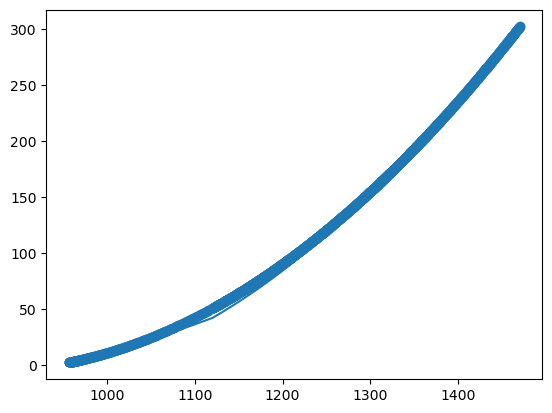

In [238]:
plt.scatter(eos[24][1],eos[24][0])
plt.plot(mu_total[24],p_total[24])

In [239]:
min_distance_points_1[60]

[(1506.1874961005672, 302.6166888433752),
 (1506.1874961005672, 302.616688843367),
 (1506.1874961005672, 302.61668983746614),
 (1506.1874961005672, 302.6166898374772),
 (1506.1874961005672, 302.6166888433425),
 (1506.1874961005672, 302.61668884333443),
 (1506.1874961005672, 302.6166888433262),
 (1506.1874961005672, 302.616689837521),
 (1506.1874961005672, 302.6166898375319),
 (1506.1874961005672, 302.6166888433015),
 (1506.1874961005672, 302.61668884329345),
 (1506.1874961005672, 302.61668884328503),
 (1506.1874961005672, 302.61668983757585),
 (1506.1874961005672, 302.6166898375867),
 (1506.1874961005672, 302.6166898375976),
 (1506.1874961005672, 302.6166888432525),
 (1506.1874961005672, 302.6166888432442),
 (1506.1874961005672, 302.6166898376305),
 (1506.1874961005672, 302.6166898376414),
 (1506.1874961005672, 302.6166898376524),
 (1506.1874961005672, 302.61668884321153),
 (1506.1874961005672, 302.6166888432034),
 (1506.1874961005672, 302.6166898376854),
 (1506.1874961005672, 302.6166

In [289]:
import numpy as np

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    return n_quad, e_quad

# Lists to store results
n_quad_list = []
e_quad_list = []

# Loop through eos data
for i in range(25):
    n_quad, e_quad = compute_n_e(eos[i][0], eos[i][1])
    n_quad_list.append(n_quad)
    e_quad_list.append(e_quad)

In [272]:
from TOV_Solver import generate_mr_curve
from EOS_construction import constructing_EOS

In [273]:
radii, masses, compacts, love_nums = [0]*len(e_quad), [0]*len(e_quad), [0]*len(e_quad), [0]*len(e_quad)

In [290]:
for i in range(len(e_quad)):
    e_arr = e_quad_list[i]
    p_arr = eos[i][0]
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(e_arr, p_arr)

IndexError: list index out of range

In [293]:
len(e_quad_list)

25

In [295]:
radii_1, masses_1, compacts_1, love_nums_1 = [0]*len(e_total), [0]*len(e_total), [0]*len(e_total), [0]*len(e_total)

In [301]:
for i in range(len(e_total)):
    e_arr = e_total[i]
    p_arr = p_total[i]
    radii_1[i], masses_1[i], compacts_1[i], love_nums_1[i] = generate_mr_curve(e_arr, p_arr)

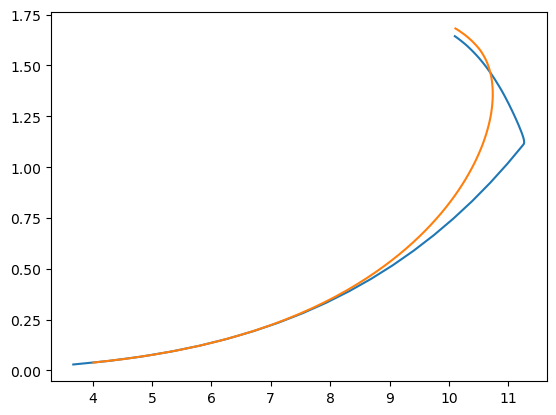

In [299]:
for _ in range(1):
    plt.plot(radii_1[10],masses_1[10])
    plt.plot(radii[10],masses[10])

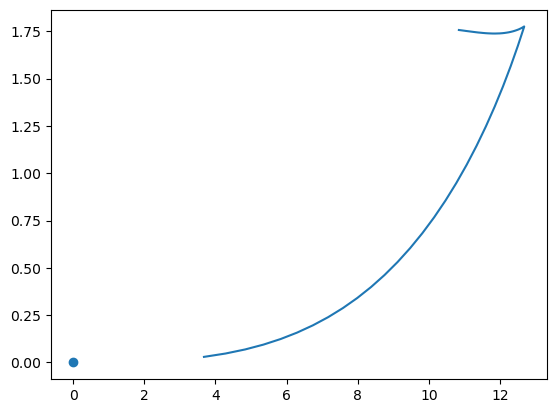

In [317]:
for _ in range(1):
    plt.plot(radii_1[45],masses_1[45])
    plt.scatter(radii[45],masses[45])
plt.show()

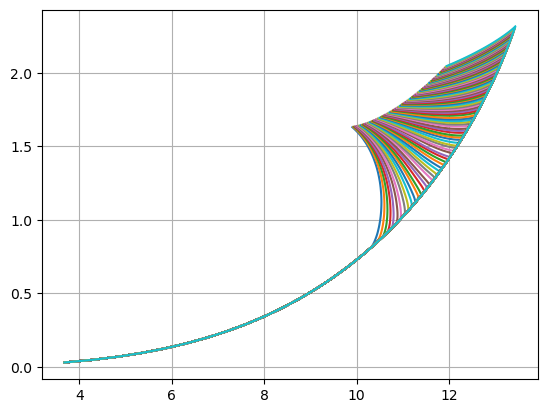

In [302]:
for i in range(len(radii_1)):
    plt.plot(radii_1[i],masses_1[i])
plt.grid()

In [310]:
type(masses[0])
twins = []
for i in range(len(masses_1)):
    max_index = masses_1[i].index(max(masses_1[i]))
    if max_index < len(masses_1[i])-1:
        twins.append(max_index)

In [311]:
len(twins)

56

In [321]:
p_total[10]==eos[10][0]

array([False, False, False, ...,  True,  True,  True])

In [ ]:
list()

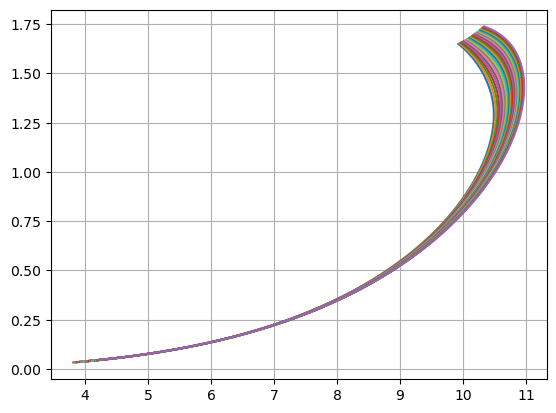

In [294]:
for i in range(25):
    plt.plot(radii[i],masses[i])
plt.grid()

ValueError: x and y must have same first dimension, but have shapes (1701,) and (1699,)

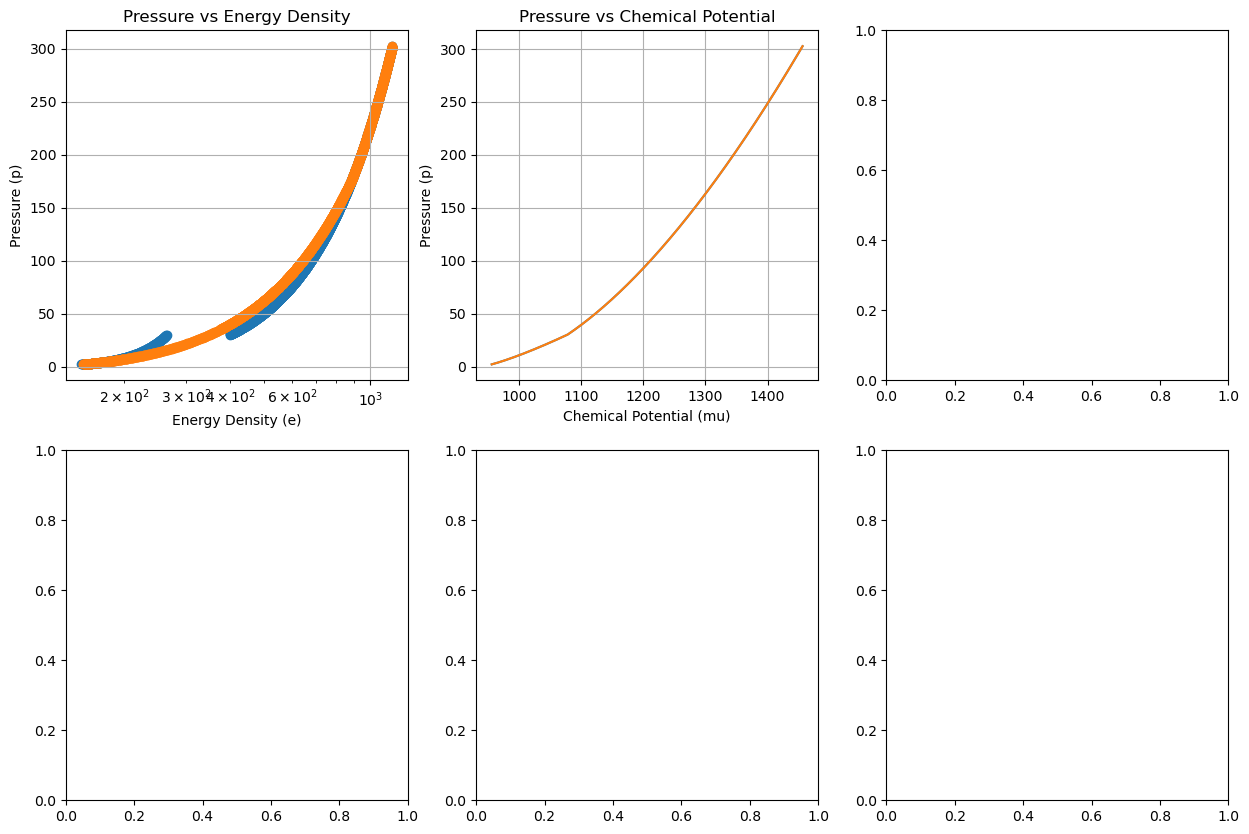

In [340]:
import matplotlib.pyplot as plt

def plot_eos(i, e_total, p_total, mu_total, cs_total, radii_1, masses_1):
    """
    Plots various properties of the Equation of State (EOS) for a given index.

    Parameters:
    - i: int, index of the EOS to plot
    - e_total: list of energy density values for different EOSs
    - p_total: list of pressure values for different EOSs
    - mu_total: list of chemical potential values for different EOSs
    - cs_total: list of sound speed values for different EOSs
    - generate_mr_curve: function that generates mass-radius data for an EOS
    """

    # Create a 2x3 grid of subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i][:-1])
    axes[0, 0].scatter(e_quad_list[i], eos[i][0][:-1])
    axes[0, 0].set_title('Pressure vs Energy Density')
    axes[0, 0].set_xlabel('Energy Density (e)')
    axes[0, 0].set_ylabel('Pressure (p)')
    axes[0, 0].set_xscale('log')
    axes[0, 0].grid(True)

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])
    axes[0, 1].plot(eos[i][1], p_total[i])
    axes[0, 1].set_title('Pressure vs Chemical Potential')
    axes[0, 1].set_xlabel('Chemical Potential (mu)')
    axes[0, 1].set_ylabel('Pressure (p)')
    axes[0, 1].grid(True)

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])
    axes[1, 0].set_title('Chemical Potential vs Sound Speed')
    axes[1, 0].set_ylabel('Sound Speed (cs)')
    axes[1, 0].set_xlabel('Chemical Potential (mu)')
    axes[1, 0].grid(True)

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])
    axes[1, 1].set_title('Energy Density vs Sound Speed')
    axes[1, 1].set_ylabel('Sound Speed (cs)')
    axes[1, 1].set_xlabel('Energy Density (e)')
    axes[1, 1].set_xscale('log')
    axes[1, 1].grid(True)

    # Plot 5: Mass-Radius (M-R) Curve
    radii_111, masses_111, _, _ = generate_mr_curve(e_total[i], p_total[i])
    radii_112, masses_112, _, _ = generate_mr_curve(e_quad_list[i], p_total[i])
    axes[0, 2].plot(radii_111, masses_111, label=f'EOS {i+1}')
    axes[0, 2].plot(radii_112, masses_112, label=f'EOS {i+1}')
    axes[0, 2].set_title('Mass-Radius Curve')
    axes[0, 2].set_xlabel('Radius (km)')
    axes[0, 2].set_ylabel('Mass (M_sun)')
    axes[0, 2].legend()
    axes[0, 2].grid(True)

    # Adjust layout and show the plot
    plt.suptitle(f'Equation of State {i+1}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


plot_eos(i=10, e_total=e_total, p_total=p_total, mu_total=mu_total, cs_total=cs_total, radii_1=radii_1, masses_1=masses_1)

In [211]:
Del_p = [P_optimal_1[i][0] / P_crit[i] for i in range(len(P_optimal_1))]

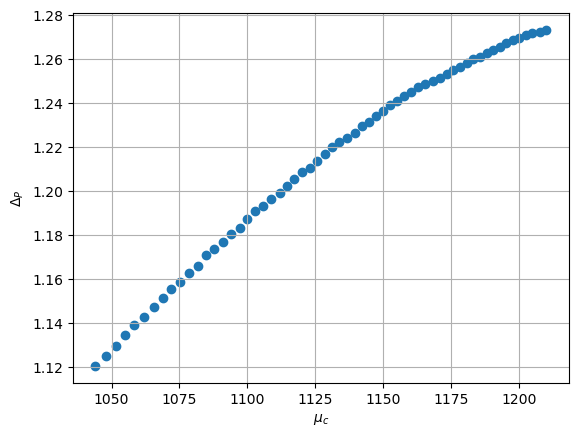

In [213]:
plt.scatter(mu_crit[:60],Del_p[:60]);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta_{P} $');
plt.show();

In [25]:
# Lists to store results
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []
delta_P_Points = []
delta_P_optimal_max = []
P_all_max = []

# Store first values of a_opt and b_opt
a_opt_first_values = []
b_opt_first_values = []

# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index] * (1 + 0.01)
    P_crit_2 = P_crit[index] * (1 + 0.3)
    P_crit_new = np.linspace(P_crit_1, P_crit_2, 1000)
    delta_P = np.linspace(P_crit[index] * 0.01, P_crit[index] * 0.3, 1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index], P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue

    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    delta_P_optimal = np.array(delta_P_optimal)
    min_distance_points = np.array(min_distance_points)

    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index_min = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index_min])
        P_all_1.append(P_optimal[0])

        P_max_points.append(min_distance_points[index_min])
        P_max_points_1.append(min_distance_points[0])
        delta_P_Points.append(delta_P_optimal[0])
        delta_P_optimal_max.append(delta_P_optimal[-1])
        P_all_max.append(P_optimal[-1])

        # Save the first values of a_opt and b_opt
        a_opt_first_values.append(a_optimal[0])
        b_opt_first_values.append(b_optimal[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)
        a_opt_first_values.append(0)
        b_opt_first_values.append(0)

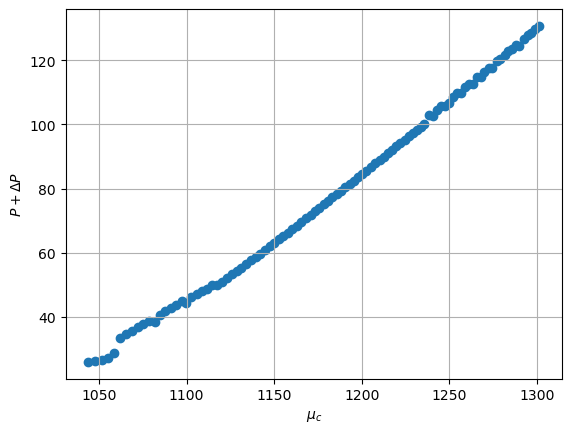

In [26]:
plt.scatter(mu_crit,P_all);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

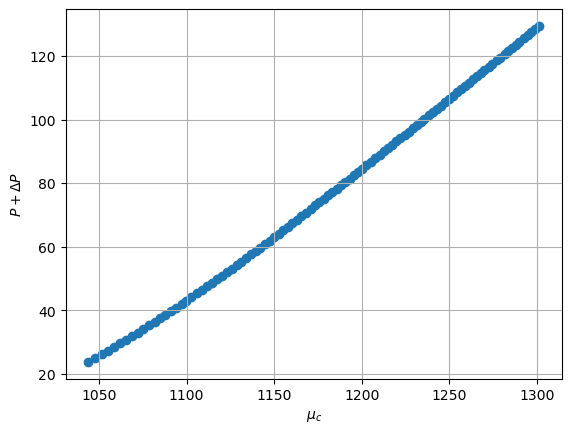

In [27]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [29]:
del_p = np.array(delta_P_Points)/np.array(P_crit)

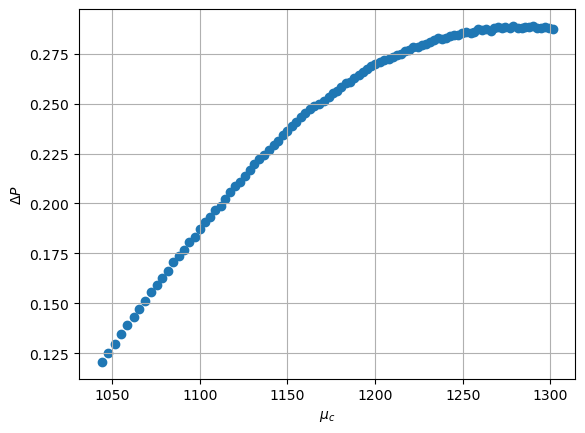

In [30]:
plt.scatter(mu_crit,del_p);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

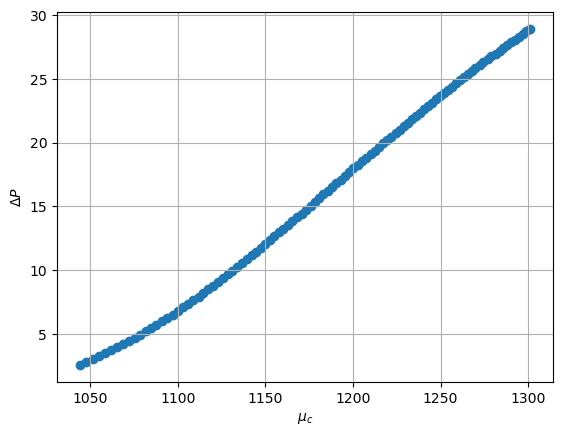

In [65]:
plt.scatter(mu_crit,delta_P_Points);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

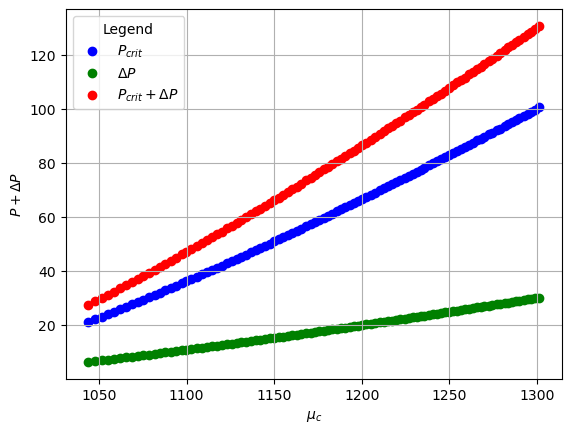

In [66]:
# Plotting the scatter points
plt.scatter(mu_crit, P_crit, label=r"$P_{crit}$", color='b')
plt.scatter(mu_crit, delta_P_optimal_max, label=r"$\Delta P$", color='g')
plt.scatter(mu_crit, P_all_max, label=r"$P_{crit} + \Delta P$", color='r')

# Adding grid, labels, and legend
plt.grid()
plt.xlabel(r'$\mu_c$')
plt.ylabel(r'$P + \Delta P$')

# Display the legend to label the lines
plt.legend(title='Legend', loc='best')

# Show the plot
plt.show()


In [67]:
len(delta_P_optimal_max)

100

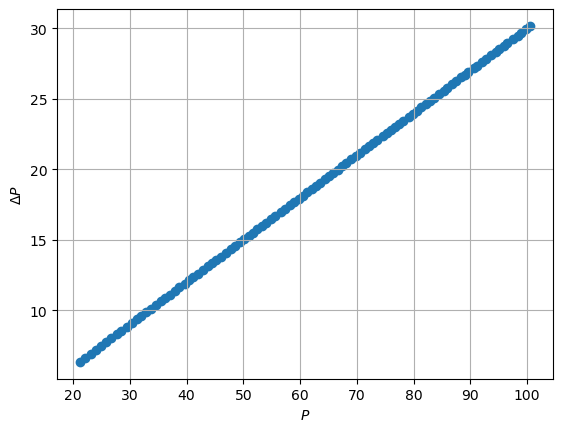

In [68]:
plt.scatter(P_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$P$');
plt.ylabel(r'$\Delta P $');
plt.show();

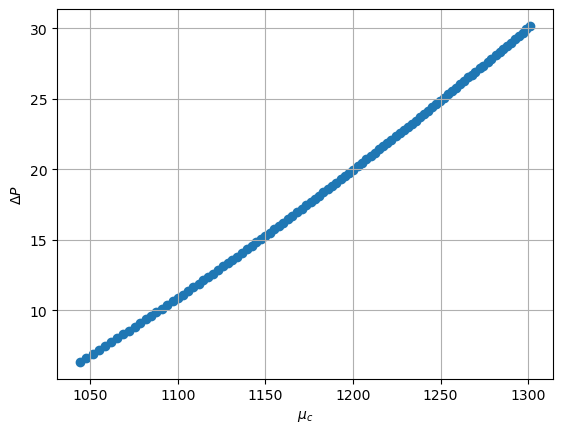

In [69]:
plt.scatter(mu_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

 Curve Fit

In [ ]:
import pandas as pd

# Create a DataFrame
df = pd.DataFrame({'Column1': list1, 'Column2': list2, 'Column3': list3})

# Save to Excel
df.to_excel("output.xlsx", index=False)